## Backtest resutls and visualization

Backtest resutls for strategies saved in the `results/run` directory. The notebook visualizes out of sample returns for the different strategies and summarizes the following metrics: 
- Expected shortfall at 80% confidence level (ES80)
- Expected shortfall at 95% confidence level (ES95)
- Annualized volatility (Vol)
- Sharpe ratio (SR)
- Soritno ratio (SOR)
- Maximum drawdown (MD)
- Expected shortfall ratio (ESR)
- Average asset turnover (AAT)
- Average currency turnover (ACT)

In [1]:
import os
import json

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

RUNS_DIR = "../../results/runs"
OPTIMIZER_RUN_DIRS = [f"{RUNS_DIR}/{d}" for d in os.listdir(RUNS_DIR) if os.path.isdir(f"{RUNS_DIR}/{d}")]
RUN_TO_UNIVERSE_SIZE = {"1":10, "2":50, "3":100}

# Expected shortfall optimization

### Metrics summary table for expected shortfall optimization backtested on increasing unvierses sizes

In [2]:
es_metrics = {}

for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  # only first 3 runs for each universe size
        json_path = f"{run_dir}/{run_num}/metrics.json"
        with open(json_path) as f:
            es_metrics[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = json.load(f)

# Construct and visualize a table of 3 panels for the 3 different universe sizes
es_metrics = pd.DataFrame.from_dict(es_metrics, orient="index")
columns = ["ES80","ES_95",  "Vol", "MD", "SR", "SOR", "ESR", "AAT", "ACT"]
es_metrics.columns = columns

es_metrics.index = es_metrics.index.set_levels(
    es_metrics.index.levels[1].astype(int), level=1
)
sizes = sorted(es_metrics.index.get_level_values(1).unique()) 
panels = {size: es_metrics.xs(size, level=1) for size in sizes}
panels = {size: es_metrics.xs(size, level=1).T for size in sizes}
for size in sizes:
    panels[size].columns = [c.split('/')[-1] for c in panels[size].columns]

strategy_order = ['equal_weight_optimizer', 'reg_es_asset_full', 'reg_es_asset_zero', "es_curr_overlay", "reg_es_curr_overlay", "es_joint", "reg_es_joint"] 
panels = {size: panels[size][strategy_order] for size in sizes}

In [3]:
for size in sizes:
    print(f"Universe size: {size}")
    display(panels[size].round(4))

Universe size: 10


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,1.1540,0.7850,0.9597,0.6730,0.7039,0.6595,0.7751
ES_95,NaN,1.4787,1.7801,1.2010,1.2865,1.1699,1.4611
Vol,13.9564,9.5699,11.8373,8.0521,8.3654,7.8785,9.4348
MD,54.7697,43.3678,52.3388,29.2866,35.5934,29.2272,42.9658
SR,0.1271,0.1704,0.2139,0.0976,0.1348,0.0925,0.1652
SOR,0.1739,0.2281,0.2924,0.1320,0.1823,0.1262,0.2209
ESR,0.0968,0.1309,0.1662,0.0736,0.1009,0.0696,0.1266
AAT,0.1493,0.2097,0.2069,0.4746,0.2096,0.4809,0.1921
ACT,0.9182,0.8892,0.0000,2.5245,1.4337,3.0021,0.9094


Universe size: 50


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,1.0399,0.4641,0.6885,0.4232,0.4478,0.4208,0.4618
ES_95,NaN,0.9551,1.3031,0.8225,0.9118,0.8115,0.9510
Vol,12.5001,6.0929,8.4999,5.5826,5.8151,5.5105,6.0599
MD,55.7457,40.4941,45.6602,40.4351,39.4677,37.6769,40.4857
SR,0.3270,0.5895,0.5302,0.6115,0.5962,0.6211,0.5867
SOR,0.4419,0.7591,0.7165,0.8361,0.7722,0.8486,0.7558
ESR,0.2476,0.4875,0.4123,0.5081,0.4877,0.5123,0.4850
AAT,0.1360,0.3122,0.3415,0.5959,0.3039,0.6100,0.2865
ACT,0.9156,0.9331,0.0000,1.1914,1.0083,1.7191,0.9390


Universe size: 100


,equal_weight_optimizer,reg_es_asset_full,reg_es_asset_zero,es_curr_overlay,reg_es_curr_overlay,es_joint,reg_es_joint
ES80,0.9717,0.3639,0.6019,0.3335,0.3593,0.3311,0.3610
ES_95,NaN,0.7695,1.1434,0.6649,0.7550,0.6554,0.7630
Vol,11.6638,4.8716,7.5018,4.4973,4.7568,4.4207,4.8387
MD,56.2640,40.7661,43.7234,31.5926,40.3742,30.8392,40.7690
SR,0.3654,0.8676,0.6108,0.7120,0.8775,0.7841,0.8901
SOR,0.4889,1.0884,0.8253,0.9288,1.1046,1.0349,1.1184
ESR,0.2763,0.7317,0.4795,0.6047,0.7319,0.6595,0.7515
AAT,0.1385,0.3562,0.4199,0.6290,0.3693,0.6383,0.3356
ACT,0.9084,0.9490,0.0000,0.9698,0.9765,1.4082,0.9518


### Cumulative returns of expected shortfall optimization backtested on increasing unvierses sizes

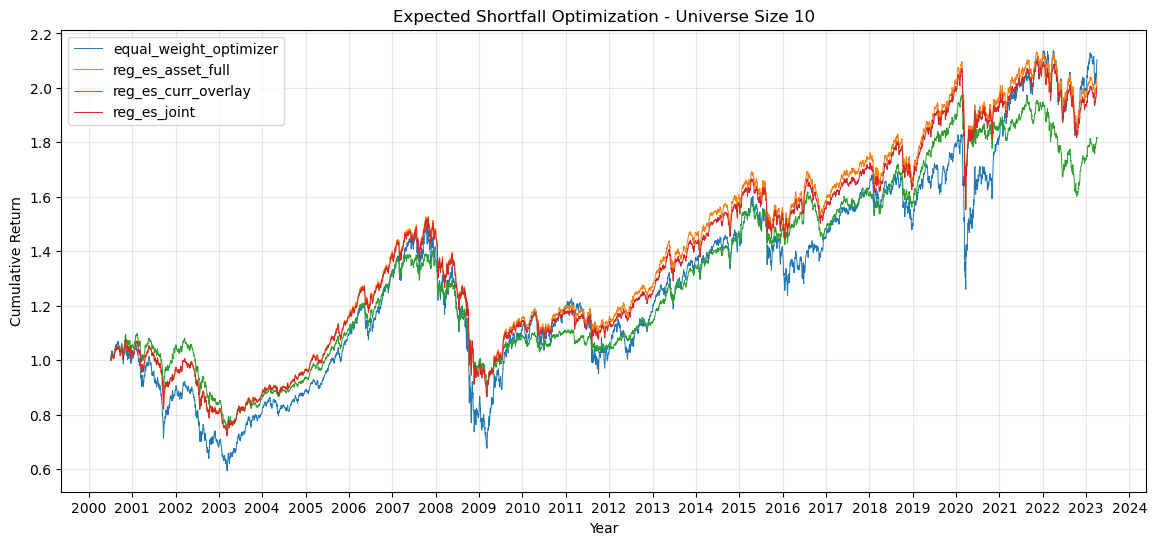

In [4]:
es_returns = {}
for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  
        json_path = f"{run_dir}/{run_num}/oos_returns.csv" 
        es_returns[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = pd.read_csv(json_path, index_col=0, parse_dates=True)
strategies = ['equal_weight_optimizer', 'reg_es_asset_full', "reg_es_curr_overlay", "reg_es_joint"] 


# Expected shortfall optimization cumulative returns plot, universe size 10
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_10 = (1 + es_returns[(f"runs/{strategy}", 10)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_10.index, es_cumulative_returns_10, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 10")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


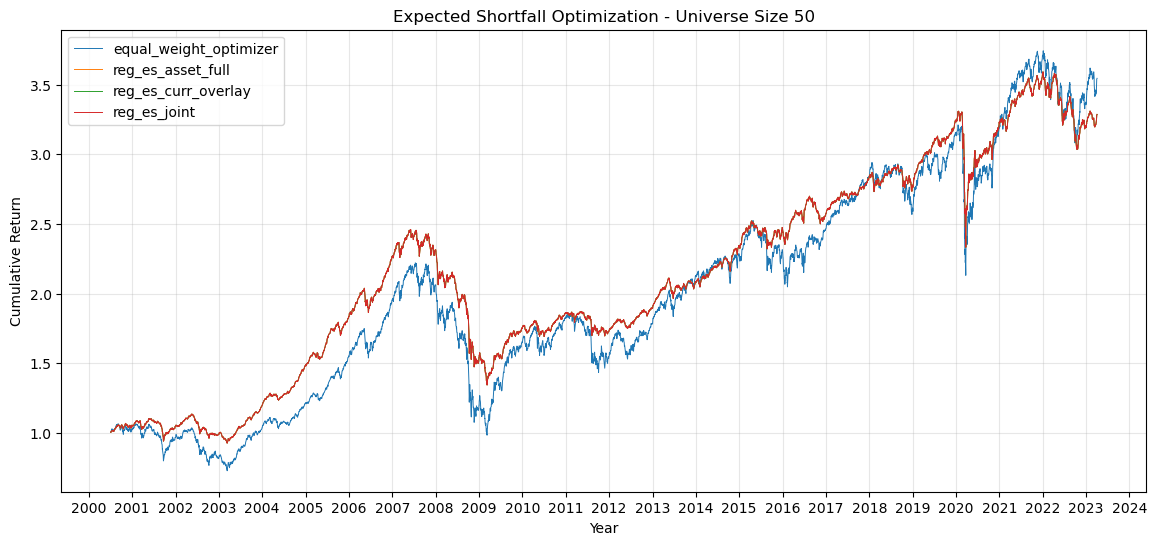

In [35]:
# Expected shortfall optimization cumulative returns plot, universe size 50
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_50 = (1 + es_returns[(f"runs/{strategy}", 50)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_50.index, es_cumulative_returns_50, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 50")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

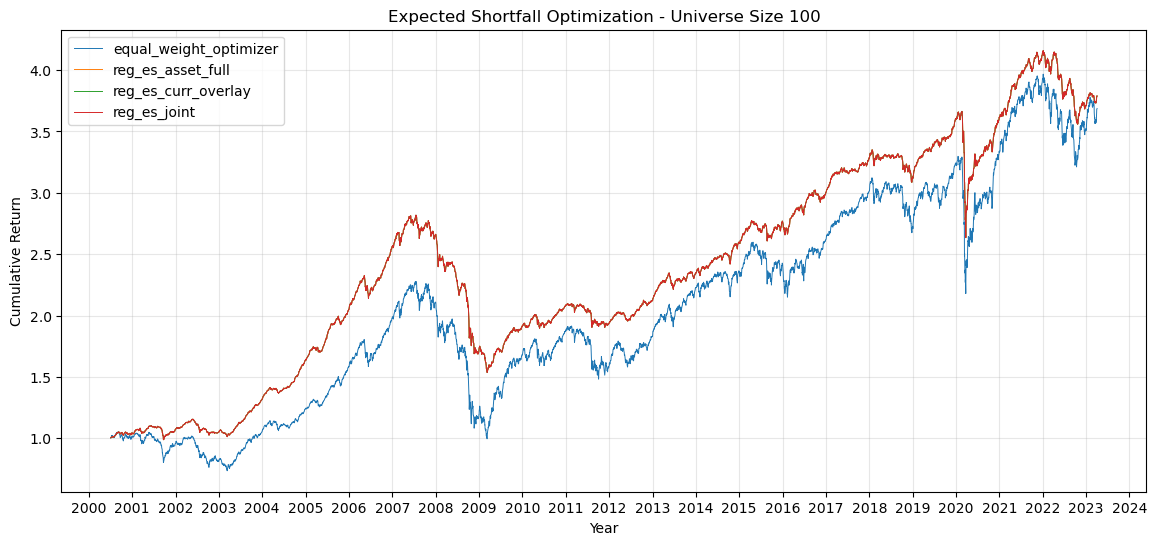

In [36]:
# Expected shortfall optimization cumulative returns plot, universe size 100
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    es_cumulative_returns_100 = (1 + es_returns[(f"runs/{strategy}", 100)]["return"]).cumprod()
    ax.plot(es_cumulative_returns_100.index, es_cumulative_returns_100, label=strategy, linewidth=0.7)
ax.set_title("Expected Shortfall Optimization - Universe Size 100")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

# Mean-variance strategies

### Metrics summary table for mean-variance strategies backtested on increasing universe sizes

In [5]:
mv_metrics = {}

for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  # only first 3 runs for each universe size
        json_path = f"{run_dir}/{run_num}/metrics.json"
        with open(json_path) as f:
            mv_metrics[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = json.load(f)

# Construct and visualize a table of 3 panels for the 3 different universe sizes
mv_metrics = pd.DataFrame.from_dict(mv_metrics, orient="index")
columns = ["ES80","ES_95", "Vol", "MD", "SR", "SOR", "ESR", "AAT", "ACT"]
mv_metrics.columns = columns

mv_metrics.index = mv_metrics.index.set_levels(
    mv_metrics.index.levels[1].astype(int), level=1
)
sizes = sorted(mv_metrics.index.get_level_values(1).unique()) 
panels = {size: mv_metrics.xs(size, level=1) for size in sizes}
panels = {size: mv_metrics.xs(size, level=1).T for size in sizes}
for size in sizes:
    panels[size].columns = [c.split('/')[-1] for c in panels[size].columns]

strategy_order = ['equal_weight_optimizer', "reg_mv_asset_full", "reg_mv_asset_zero", "mv_curr_overlay", "reg_mv_curr_overlay", "mv_joint", "reg_mv_joint"] 
panels = {size: panels[size][strategy_order] for size in sizes}

In [6]:
for size in sizes:
    print(f"Universe size: {size}")
    display(panels[size].round(4))

Universe size: 10


,equal_weight_optimizer,reg_mv_asset_full,reg_mv_asset_zero,mv_curr_overlay,reg_mv_curr_overlay,mv_joint,reg_mv_joint
ES80,1.1540,0.9527,1.1255,0.7297,0.8444,0.7360,0.8604
ES_95,NaN,1.7928,2.0852,1.2836,1.5581,1.2924,1.5852
Vol,13.9564,11.5428,13.8152,8.6735,10.0004,8.7631,10.2130
MD,54.7697,49.3003,57.1948,30.8569,42.9277,33.0058,43.2889
SR,0.1271,0.1423,0.1739,0.1208,0.1017,0.1613,0.1224
SOR,0.1739,0.1922,0.2386,0.1656,0.1377,0.2224,0.1662
ESR,0.0968,0.1086,0.1345,0.0904,0.0759,0.1210,0.0915
AAT,0.1493,0.1550,0.1561,0.3787,0.1561,0.3933,0.1429
ACT,0.9182,0.8976,0.0000,4.9646,1.3558,5.4642,1.3793


Universe size: 50


,equal_weight_optimizer,reg_mv_asset_full,reg_mv_asset_zero,mv_curr_overlay,reg_mv_curr_overlay,mv_joint,reg_mv_joint
ES80,1.0399,0.6762,0.8852,0.5661,0.6297,0.5951,0.6344
ES_95,NaN,1.3320,1.6855,1.0712,1.2214,1.1218,1.2254
Vol,12.5001,8.3315,10.9059,7.0974,7.6213,7.4885,7.6913
MD,55.7457,47.9404,55.5229,43.0180,45.5529,43.1813,45.8281
SR,0.3270,0.4344,0.4277,0.4500,0.4247,0.4649,0.4717
SOR,0.4419,0.5678,0.5788,0.6131,0.5561,0.6379,0.6207
ESR,0.2476,0.3372,0.3319,0.3554,0.3238,0.3685,0.3602
AAT,0.1360,0.1654,0.1719,0.4736,0.1886,0.4960,0.1334
ACT,0.9156,0.9054,0.0000,4.5108,1.0573,5.2067,1.0760


Universe size: 100


,equal_weight_optimizer,reg_mv_asset_full,reg_mv_asset_zero,mv_curr_overlay,reg_mv_curr_overlay,mv_joint,reg_mv_joint
ES80,0.9717,0.5715,0.7956,0.5350,0.5412,0.5675,0.5458
ES_95,NaN,1.1605,1.5221,0.9987,1.0913,1.0607,1.0946
Vol,11.6638,7.1222,9.8264,6.7135,6.6590,7.1226,6.7320
MD,56.2640,48.6032,54.8137,40.0177,47.2293,41.4982,47.4527
SR,0.3654,0.5869,0.4845,0.6277,0.5873,0.6190,0.6332
SOR,0.4889,0.7508,0.6538,0.8621,0.7517,0.8527,0.8153
ESR,0.2763,0.4608,0.3770,0.4962,0.4552,0.4894,0.4920
AAT,0.1385,0.1736,0.1927,0.5000,0.1966,0.5251,0.1403
ACT,0.9084,0.9165,0.0000,4.4741,1.0083,5.1549,1.0360


### Cumulative returns of mean variance optimization backtested on increasing unvierses sizes

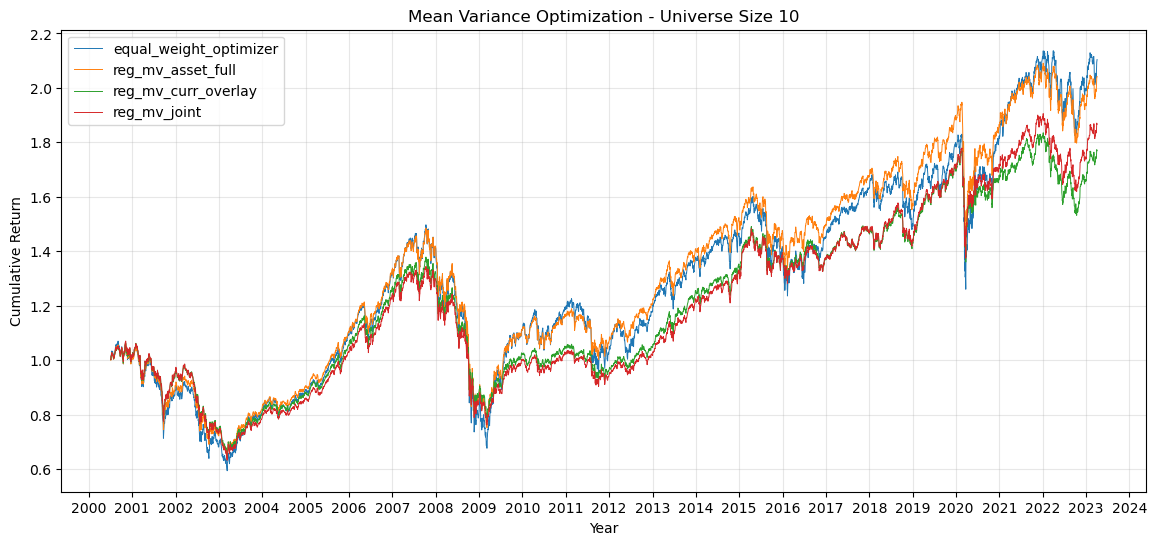

In [7]:
mv_returns = {}
for run_dir in OPTIMIZER_RUN_DIRS:
    run_nums = os.listdir(run_dir)
    for run_num in run_nums[:3]:  
        json_path = f"{run_dir}/{run_num}/oos_returns.csv" 
        mv_returns[(run_dir, RUN_TO_UNIVERSE_SIZE[run_num[-1]])] = pd.read_csv(json_path, index_col=0, parse_dates=True)
strategies = ['equal_weight_optimizer', 'reg_mv_asset_full', "reg_mv_curr_overlay", "reg_mv_joint"] 


# Mean variance optimization cumulative returns plot, universe size 10
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    mv_cumulative_returns_10 = (1 + mv_returns[(f"runs/{strategy}", 10)]["return"]).cumprod()
    ax.plot(mv_cumulative_returns_10.index, mv_cumulative_returns_10, label=strategy, linewidth=0.7)
ax.set_title("Mean Variance Optimization - Universe Size 10")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


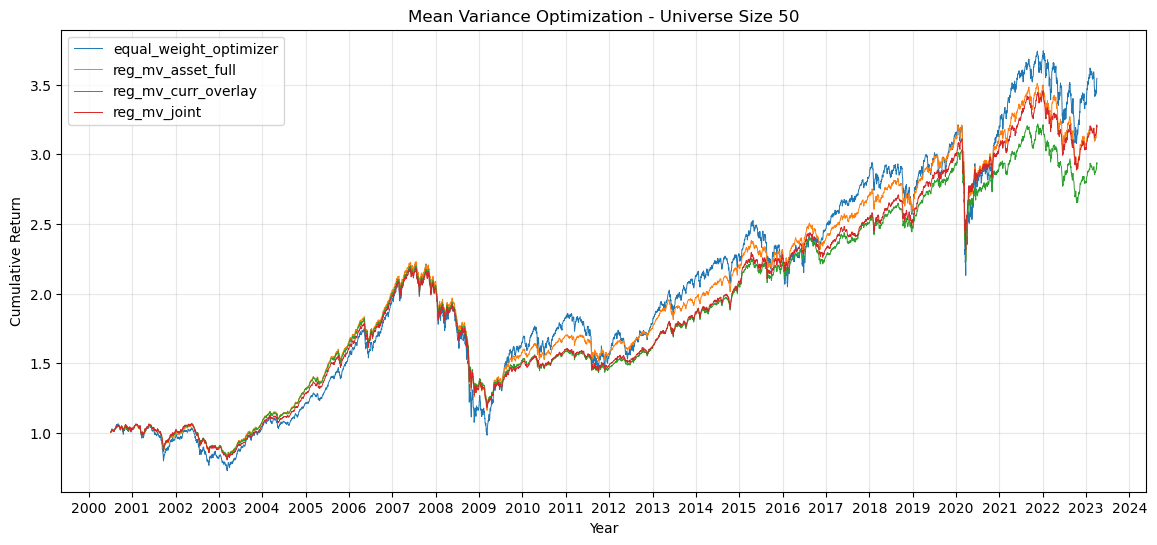

In [8]:
# Mean variance optimization cumulative returns plot, universe size 50
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    mv_cumulative_returns_50 = (1 + mv_returns[(f"runs/{strategy}", 50)]["return"]).cumprod()
    ax.plot(mv_cumulative_returns_50.index, mv_cumulative_returns_50, label=strategy, linewidth=0.7)
ax.set_title("Mean Variance Optimization - Universe Size 50")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

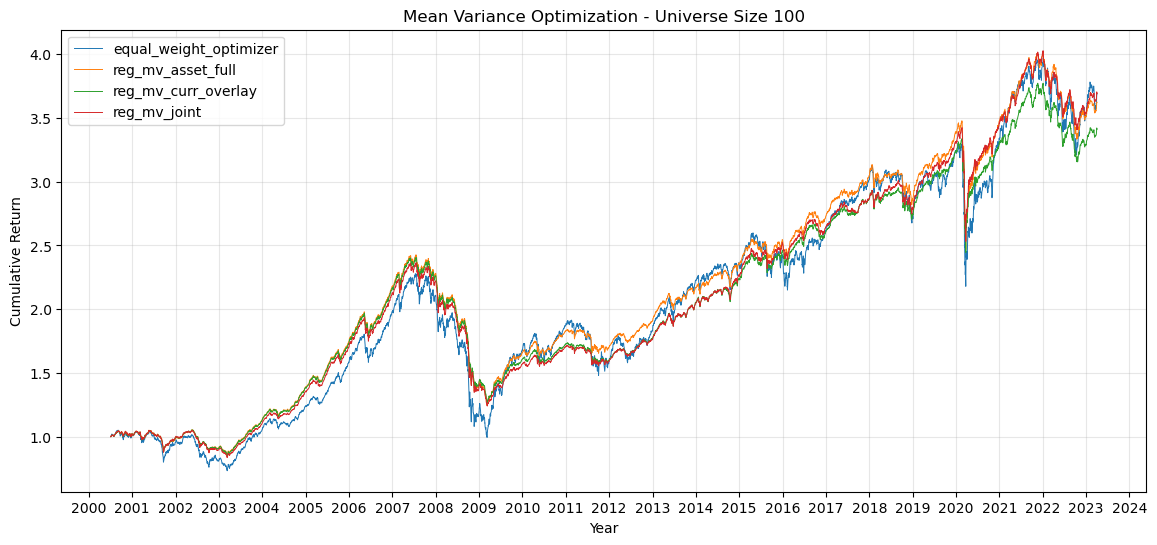

In [9]:
# Mean variance optimization cumulative returns plot, universe size 100
fig, ax = plt.subplots(figsize=(14, 6))
for strategy in strategies:
    mv_cumulative_returns_100 = (1 + mv_returns[(f"runs/{strategy}", 100)]["return"]).cumprod()
    ax.plot(mv_cumulative_returns_100.index, mv_cumulative_returns_100, label=strategy, linewidth=0.7)
ax.set_title("Mean Variance Optimization - Universe Size 100")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative Return")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()